# Wall Loss Tutorial: Spherical vs Rectangular Chambers

Learn how to configure wall loss strategies, compare chamber geometries,
and chain wall loss with coagulation and condensation. All examples run
quickly (≤30 s) with small grids and reuse helper functions to avoid
recomputing simulations.

## Setup
- Uses particula public APIs from `par.dynamics` re-exports.
- Time grid: 0–30 min with 30 s spacing (61 points).
- Distribution: preset discrete radius bins (small and fast).
- Plots: minutes on x-axis; log-scale concentrations.

In [1]:
import numpy as np
import particula as par
from matplotlib import pyplot as plt
from particula.dynamics.condensation.species_mapping import (
    CondensationSpeciesMap,
)

np.set_printoptions(precision=3, suppress=True)
TIME_STEP = 30.0  # seconds
TOTAL_TIME = 1800.0  # seconds (30 minutes)
N_STEPS = int(TOTAL_TIME / TIME_STEP)
TIME_GRID = np.linspace(0.0, TOTAL_TIME, N_STEPS + 1)
TEMPERATURE = 298.15  # K
PRESSURE = 101325.0  # Pa

In [2]:
def build_aerosol() -> par.Aerosol:
    """Create native bins spanning the two modes with zero initial gas.

    This composition example uses 10 nm–10 µm rather than the preset's
    1 nm–100 µm grid: negligible tails on the wider grid can make the
    interpolated coagulation rate negative at depleted bins. Native
    admission rejects that state; this example does not clamp it away.
    """
    particles = par.particles.create_lognormal_binned_particle_data(
        distribution_type="discrete", radius_bins=np.logspace(-8, -5, 150)
    )
    gas = par.gas.GasData(
        name=["PlaceholderPartitioning", "PlaceholderGasOnly"],
        molar_mass=np.array([0.018, 0.028]),
        partitioning=np.array([True, False]),
        concentration=np.zeros((1, 2)),
    )
    environment = par.gas.EnvironmentData(
        temperature=np.array([TEMPERATURE]),
        pressure=np.array([PRESSURE]),
        saturation_ratio=np.zeros((1, 2)),
    )
    return par.Aerosol(particles=particles, gas=gas, environment=environment)


def safe_substeps(strategy, aerosol, duration):
    """Bound explicit Euler loss for the current particle sizes."""
    coefficient = strategy.loss_coefficient(
        aerosol.particles, temperature=TEMPERATURE, pressure=PRESSURE
    )
    return max(1, int(np.ceil(np.max(coefficient) * duration / 0.9)))


def run_wall_loss(strategy: par.dynamics.WallLossStrategy, sub_steps: int = 1):
    """Execute wall loss over the shared time grid."""
    aerosol = build_aerosol()
    sub_steps = max(sub_steps, safe_substeps(strategy, aerosol, TIME_STEP))
    wall_loss = par.dynamics.WallLoss(wall_loss_strategy=strategy)
    series = np.zeros_like(TIME_GRID)
    series[0] = aerosol.particles.number_density[0]
    for idx in range(1, TIME_GRID.size):
        aerosol = wall_loss.execute(
            aerosol, time_step=TIME_STEP, sub_steps=sub_steps
        )
        series[idx] = aerosol.particles.number_density[0]
    return series, aerosol


def plot_decay(times_min, *series_with_labels):
    fig, ax = plt.subplots(figsize=(6, 4))
    for series, label, style in series_with_labels:
        ax.plot(times_min, series / series[0], style, label=label, linewidth=2)
    ax.set_xlabel("Time (min)")
    ax.set_ylabel("Normalized concentration")
    ax.set_yscale("log")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    return fig, ax


times_minutes = TIME_GRID / 60.0
baseline_aerosol = build_aerosol()
print("Initial bins:", baseline_aerosol.particles.radii[0].size)
print(
    "Initial total conc (1/m^3):",
    f"{baseline_aerosol.particles.number_density[0]:.3e}",
)

Initial bins: 150
Initial total conc (1/m^3): 1.100e+10


## Basic spherical wall loss
Spherical chamber with modest eddy diffusivity and radius. Uses two
substeps to satisfy the native nonnegative Euler update requirement.

In [3]:
spherical_strategy = par.dynamics.SphericalWallLossStrategy(
    wall_eddy_diffusivity=1e-3,
    chamber_radius=0.5,
    distribution_type="discrete",
)
spherical_series, spherical_aerosol = run_wall_loss(
    spherical_strategy, sub_steps=2
)
print("Final conc (spherical):", f"{spherical_series[-1]:.3e} 1/m^3")

Final conc (spherical): 1.061e+10 1/m^3


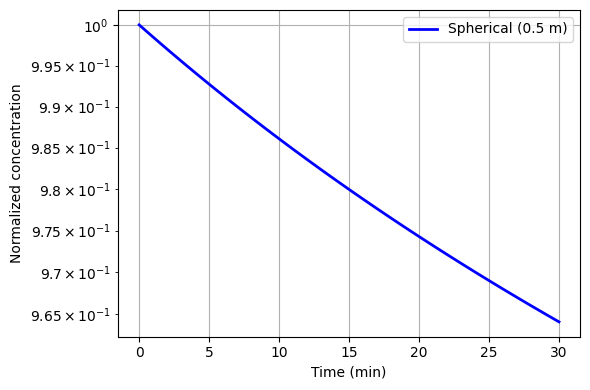

In [4]:
_ = plot_decay(
    times_minutes,
    (spherical_series, "Spherical (0.5 m)", "b-"),
)

## Geometry comparison: spherical vs rectangular
Equal-volume comparison: a 0.5 m radius sphere (~0.52 m^3) vs a rectangular
chamber with dimensions (1.0, 0.72, 0.72) m.

Text(0.5, 1.0, 'Geometry comparison')

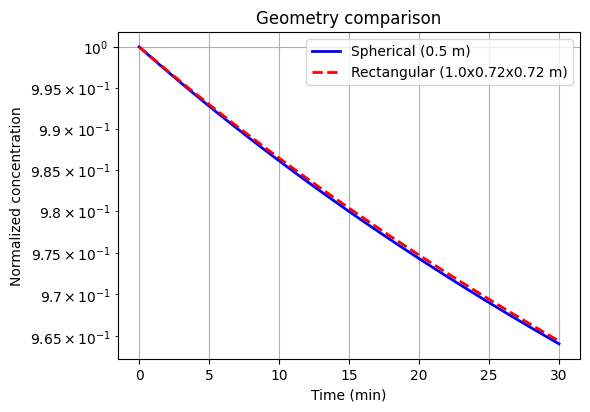

In [5]:
rectangular_strategy = par.dynamics.RectangularWallLossStrategy(
    wall_eddy_diffusivity=1e-3,
    chamber_dimensions=(1.0, 0.72, 0.72),
    distribution_type="discrete",
)
rect_series, _ = run_wall_loss(rectangular_strategy)
fig_cmp, _ = plot_decay(
    times_minutes,
    (spherical_series, "Spherical (0.5 m)", "b-"),
    (rect_series, "Rectangular (1.0x0.72x0.72 m)", "r--"),
)
fig_cmp.axes[0].set_title("Geometry comparison")

## Advanced chaining: coagulation + wall loss
Demonstrates runnable composition with the `|` operator. Uses the same time
    grid and small bin counts to keep runtime low.

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 169.22it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 179.04it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 187.57it/s]

... (110 outputs left out)

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 135.17it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 139.54it/s]

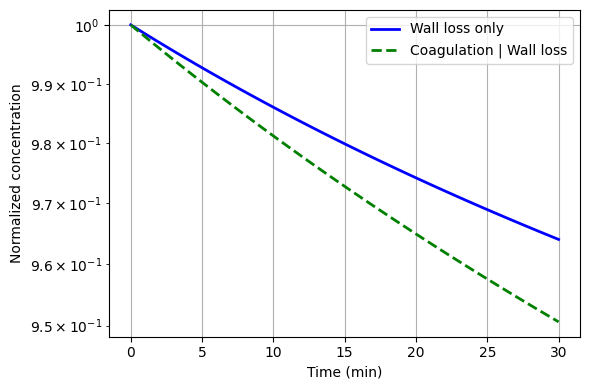

In [6]:
coag_strategy = par.dynamics.BrownianCoagulationStrategy(
    distribution_type="discrete"
)
coagulation = par.dynamics.Coagulation(coagulation_strategy=coag_strategy)
coag_wall = coagulation | par.dynamics.WallLoss(
    wall_loss_strategy=spherical_strategy
)

aerosol_wall_only = build_aerosol()
aerosol_coag_wall = build_aerosol()
wall_only_series = np.zeros_like(TIME_GRID)
coag_wall_series = np.zeros_like(TIME_GRID)
wall_only_series[0] = aerosol_wall_only.particles.number_density[0]
coag_wall_series[0] = aerosol_coag_wall.particles.number_density[0]

for idx in range(1, TIME_GRID.size):
    aerosol_wall_only = par.dynamics.WallLoss(
        wall_loss_strategy=spherical_strategy
    ).execute(
        aerosol_wall_only,
        time_step=TIME_STEP,
        sub_steps=safe_substeps(
            spherical_strategy, aerosol_wall_only, TIME_STEP
        ),
    )
    aerosol_coag_wall = coag_wall.execute(
        aerosol_coag_wall,
        time_step=TIME_STEP,
        sub_steps=safe_substeps(
            spherical_strategy, aerosol_coag_wall, TIME_STEP
        ),
    )
    wall_only_series[idx] = aerosol_wall_only.particles.number_density[0]
    coag_wall_series[idx] = aerosol_coag_wall.particles.number_density[0]

_ = plot_decay(
    times_minutes,
    (wall_only_series, "Wall loss only", "b-"),
    (coag_wall_series, "Coagulation | Wall loss", "g--"),
)

### Concise condensation + wall loss snippet
Shows a lightweight condensation strategy chained with wall loss over a
short window (10 min). Parameters are intentionally small to keep runtime
modest; this is a fixed gas reservoir, not a closed mass budget.

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 555.54it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 620.09it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 612.04it/s]

... (30 outputs left out)

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 532.75it/s]

Executing Runnable:   0%|          | 0/1 [00:00<?, ?it/s]

Executing Runnable: 100%|██████████| 1/1 [00:00<00:00, 538.35it/s]

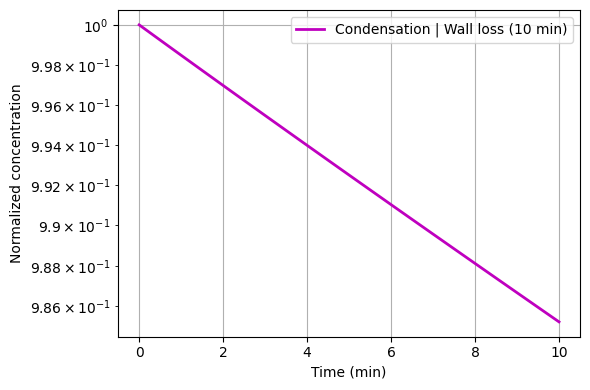

In [7]:
short_time = np.linspace(0.0, 600.0, 21)  # 10 min, 30 s spacing
cond_series = np.zeros_like(short_time)
# The former zero-gas/high-volatility placeholder could fully evaporate bins
# and was silently skipped on failure. Use an explicitly illustrative low-
# volatility organic reservoir for this runnable composition demonstration.
aerosol_cond = build_aerosol()
aerosol_cond.gas.name[0] = "illustrative-organic"
aerosol_cond.gas.molar_mass[0] = 0.12
aerosol_cond.gas.concentration[0, 0] = 1e-8
condensation_strategy = par.dynamics.CondensationIsothermal(
    molar_mass=aerosol_cond.gas.molar_mass.copy(),
    diffusion_coefficient=1e-5,
    accommodation_coefficient=0.9,
    update_gases=False,
    activity_strategy=par.particles.ActivityIdealMass(),
    surface_strategy=par.particles.SurfaceStrategyVolume(
        surface_tension=0.072,
        density=1000.0,
    ),
    vapor_pressure_strategy=[
        par.gas.ConstantVaporPressureStrategy(1e-5),
        par.gas.ConstantVaporPressureStrategy(1e3),
    ],
    species_map=CondensationSpeciesMap(tuple(aerosol_cond.gas.name), ((0, 0),)),
)
condensation = par.dynamics.MassCondensation(condensation_strategy)
wall_loss_runnable = par.dynamics.WallLoss(spherical_strategy)
cond_wall = condensation | wall_loss_runnable
cond_series[0] = aerosol_cond.particles.number_density[0]
for idx in range(1, short_time.size):
    aerosol_cond = cond_wall.execute(
        aerosol_cond,
        time_step=short_time[1] - short_time[0],
        sub_steps=safe_substeps(spherical_strategy, aerosol_cond, TIME_STEP),
    )
    cond_series[idx] = aerosol_cond.particles.number_density[0]
assert np.all(np.isfinite(cond_series))
assert np.all(np.diff(cond_series) <= 0)
_ = plot_decay(
    short_time / 60.0,
    (cond_series, "Condensation | Wall loss (10 min)", "m-"),
)

## Assertions and sanity checks
Quick guards to keep the notebook honest during headless execution.

In [8]:
# Geometry parameter validation
try:
    par.dynamics.SphericalWallLossStrategy(
        wall_eddy_diffusivity=1e-3, chamber_radius=-1.0
    )
    raise AssertionError("Expected ValueError for negative radius")
except ValueError:
    pass

try:
    par.dynamics.RectangularWallLossStrategy(
        wall_eddy_diffusivity=1e-3, chamber_dimensions=(0.0, 1.0, 1.0)
    )
    raise AssertionError("Expected ValueError for non-positive dimension")
except ValueError:
    pass

# Concentration non-negativity after simulations
for name, series in [
    ("spherical", spherical_series),
    ("rectangular", rect_series),
    ("wall only", wall_only_series),
    ("coagulation | wall", coag_wall_series),
    ("condensation | wall", cond_series),
]:
    if not np.all(series >= 0.0):
        raise AssertionError(f"Non-negative concentrations failed for {name}")

print("Assertions passed: parameter guards and non-negativity checks.")

Assertions passed: parameter guards and non-negativity checks.


## Summary
- Built reusable helpers to construct aerosols and run wall loss quickly.
- Compared spherical vs rectangular chambers over a shared time grid.
- Demonstrated chaining with coagulation and a concise condensation variant.
- Added inline assertions for invalid geometry and non-negative concentrations.